In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns

In [2]:
import data                       

In [3]:
plt.style.use("../../nice.mplstyle")

In [4]:
fig_dir = "figures"
if not os.path.isdir(fig_dir):
    os.makedirs(fig_dir)

## RMSE 

Raw-mean vs "pooled" (obs-weighted)

In [11]:
ads = xr.open_dataset("runs/v4/inference-validation/metrics/sla.nc", chunks="auto")
ads = ads.squeeze()
ads.load();

In [12]:
sds = data.open_anemoi_statistics()
sds

<xarray.Dataset> Size: 3kB
Dimensions:   (variable: 36)
Coordinates:
  * variable  (variable) object 288B 'cos_julian_day' ... 'pooled'
Data variables:
    mean      (variable) float64 288B 4.561e-05 0.8092 ... 0.03197 0.03854
    stdev     (variable) float64 288B 0.7071 0.202 0.7257 ... 0.08487 0.08641
    minimum   (variable) float64 288B -1.0 0.01276 -1.0 ... -1.14 -1.169 -1.318
    maximum   (variable) float64 288B 1.0 1.0 1.0 -5.331 ... 1.201 1.015 1.342
    sums      (variable) float64 288B 8.365e+03 1.484e+08 ... 1.123e+05 nan
    squares   (variable) float64 288B 9.169e+07 1.276e+08 ... 2.889e+04 nan
    count     (variable) float64 288B 1.834e+08 1.834e+08 ... 3.512e+06 nan
    has_nans  (variable) float64 288B 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 nan
Attributes: (12/33)
    allow_nans:                    True
    area_check_max:                1.00117641972384
    area_check_min:                0.9992095208373832
    binned:                        True
    cell_selection:                gebco.land_fraction < 0.1
    constant_fields:               ['cos_latitude', 'cos_longitude', 'elevati...
    ...                            ...
    statistics_end_date:           2014-12-31T12:00:00
    statistics_start_date:         2000-01-01T12:00:00
    time_bin_closed:               left
    time_bin_label:                middle
    variables:                     ['cos_julian_day', 'cos_latitude', 'cos_lo...
    variables_metadata:            {'cos_julian_day': {'computed_forcing': Tr...

In [13]:
ads

<xarray.Dataset> Size: 64kB
Dimensions:     (t0: 362, group: 5)
Coordinates:
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 200B 'cryosat_2' 'haiyang_2a' ... 'saral' 'pooled'
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
Data variables:
    rmse        (t0, group) float64 14kB 0.06065 0.06326 0.0597 ... nan 0.06607
    mae         (t0, group) float64 14kB 0.03595 0.03817 0.03692 ... nan 0.03995
    bias        (t0, group) float64 14kB 0.0001709 -0.0001662 ... nan -0.0005569
    n_obs       (t0, group) int64 14kB 3472 3662 3736 3667 ... 3445 3882 0 10976

In [21]:
def histplot(metric, show_stdev=False):

    fig, axs = plt.subplots(1, 2, figsize=(12,5))
    
    ax = axs[0]
    if metric =="rmse":
        pergroupmean = np.sqrt((ads[metric]**2).drop_sel(group="pooled").mean("group"))
    else:
        raise NotImplementedError
    for xds, label in zip(
        [pergroupmean, ads[metric].sel(group="pooled")],
        ["Raw Mean", "$N_{obs}$ Weighted"],
    ):
        sns.histplot(
            xds,
            ax=ax,
            label=label,
        )

    if show_stdev:
        ax.axvline(x=sds["stdev"].sel(variable="pooled"), color="gray", label="Pooled Training Std. Dev.")
    ax.legend()
    
    ax = axs[1]
    for varname in [
        "n_obs",
    ]:
        ads[varname].sel(group="pooled").plot(ax=ax, label=varname, color="C3")
        ax.set(title="")
        ax.legend()
        

    return fig, axs

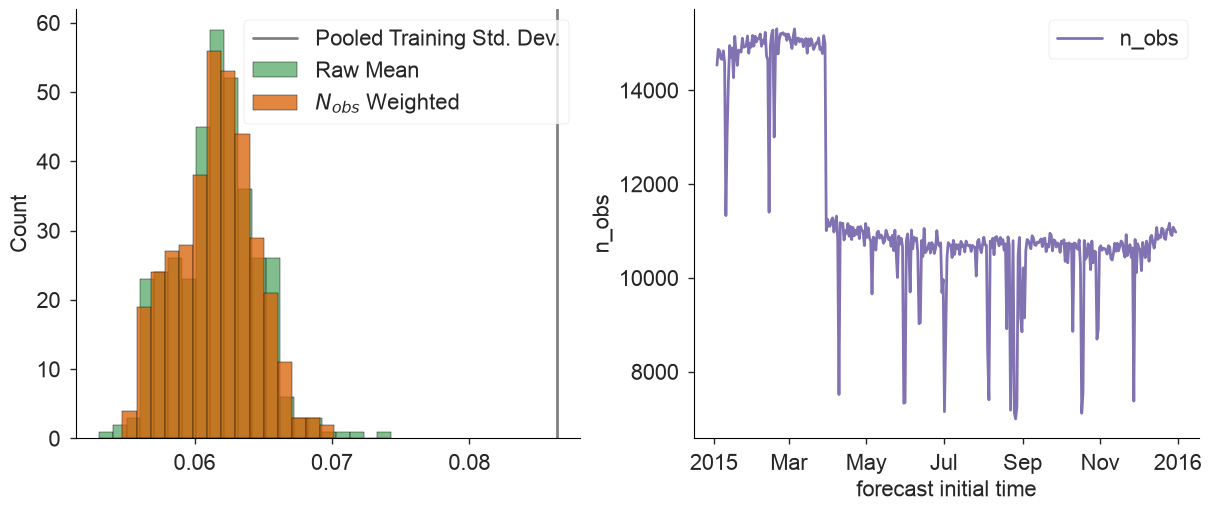

In [22]:
histplot("rmse", show_stdev=True);

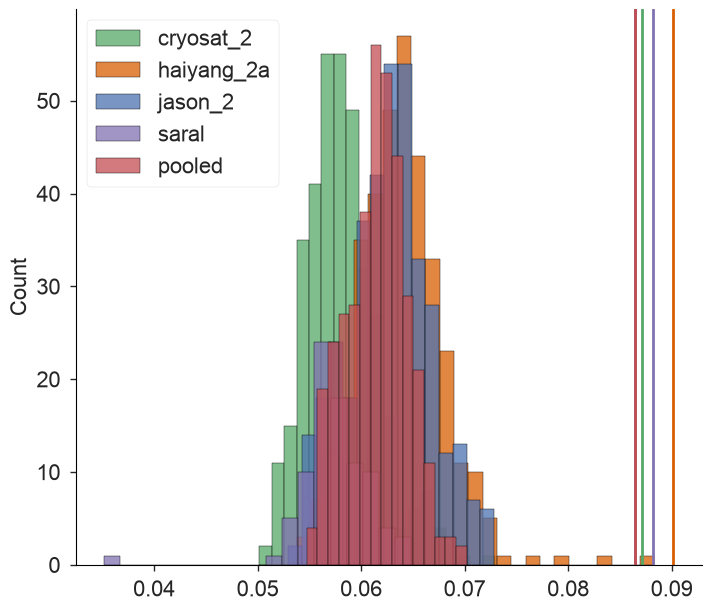

In [26]:
metric = "rmse"

fig, ax = plt.subplots()
for i, group in enumerate(ads.group.values):
    sns.histplot(
        ads[metric].sel(group=group),
        label=group,
        #alpha=.5
        color=f"C{i}",
    )
    if group != "pooled":
        ax.axvline(sds["stdev"].sel(variable=f"sla_filtered_{group}"), color=f"C{i}")
    else:
        ax.axvline(sds["stdev"].sel(variable=group), color=f"C{i}")
ax.legend();

## Observed at input

In [27]:
ods = xr.open_dataset("runs/v4/inference-validation/metrics/sla.seen_at_hour.nc")
ods = ods.squeeze()
ods.load()

<xarray.Dataset> Size: 238kB
Dimensions:       (t0: 362, group: 5, seen_at_hour: 4)
Coordinates:
  * t0            (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T...
    valid_time    (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T...
  * group         (group) <U10 200B 'cryosat_2' 'haiyang_2a' ... 'pooled'
  * seen_at_hour  (seen_at_hour) int64 32B 24 0 -24 -48
    lead_time     timedelta64[ns] 8B 1 days
    fhr           int64 8B 24
Data variables:
    rmse          (t0, group, seen_at_hour) float64 58kB 0.06666 ... 0.06001
    mae           (t0, group, seen_at_hour) float64 58kB 0.03732 ... 0.03603
    bias          (t0, group, seen_at_hour) float64 58kB -0.00325 ... -0.0003197
    n_obs         (t0, group, seen_at_hour) int64 58kB 576 1172 ... 4231 3226

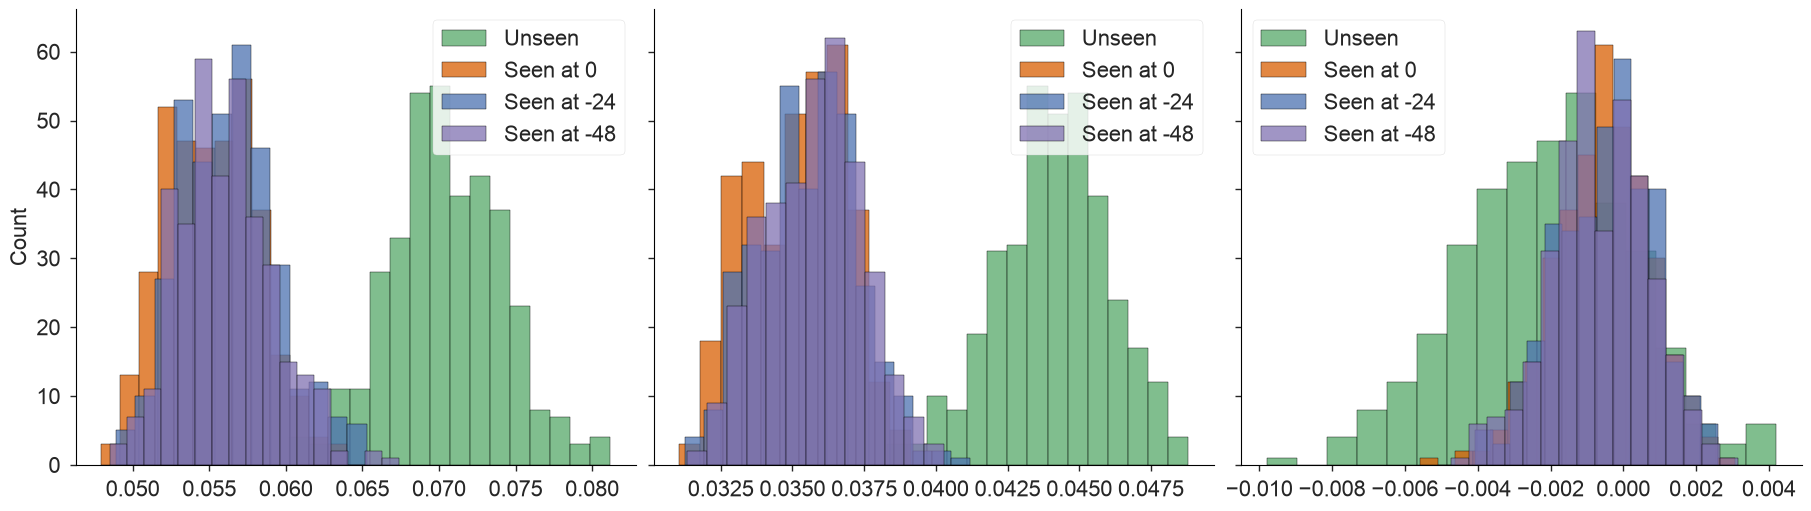

In [31]:
metric = "rmse"
metrics = ["rmse", "mae", "bias"]
ncols = len(metrics)
fig, axs = plt.subplots(1, ncols, figsize=(6*ncols,5),sharey=True)
for metric, ax in zip(metrics,axs):
    for seen_at in ods.seen_at_hour.values:
        sns.histplot(
            ods[metric].sel(seen_at_hour=seen_at, group="pooled"),
            label=f"Seen at {seen_at}" if seen_at <= 0 else "Unseen",
            #alpha=.5
            ax=ax,
        )
    ax.legend();

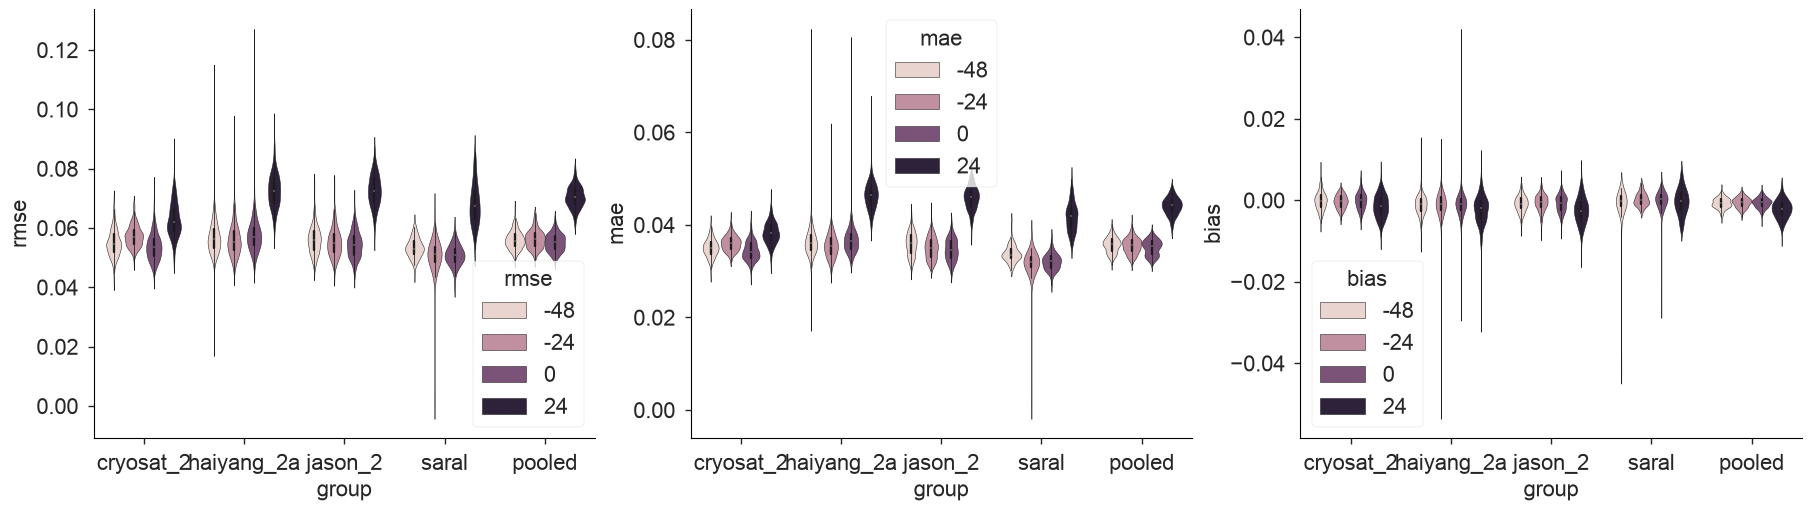

In [46]:
metric = "rmse"
metrics = ["rmse", "mae", "bias"]
ncols = len(metrics)
fig, axs = plt.subplots(1, ncols, figsize=(6*ncols,5))
for metric, ax in zip(metrics,axs):
    sns.violinplot(
        ods[metric].to_dataset().to_dataframe().reset_index(),
        y=metric,
        hue="seen_at_hour",
        x="group",
        #label=f"Seen at {seen_at}" if seen_at <= 0 else "Unseen",
        #alpha=.5
        ax=ax,
    )
    ax.legend(title=metric);

## Overlap between observing systems

In [60]:
ods = xr.open_dataset("runs/v4/inference-validation/metrics/sla.overlap.nc")
ods = ods.squeeze()
ods.load()

<xarray.Dataset> Size: 238kB
Dimensions:     (t0: 362, group: 5, overlap: 4)
Coordinates:
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 200B 'cryosat_2' 'haiyang_2a' ... 'saral' 'pooled'
  * overlap     (overlap) int64 32B 1 2 3 4
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
Data variables:
    rmse        (t0, group, overlap) float64 58kB 0.05579 0.07007 ... nan
    mae         (t0, group, overlap) float64 58kB 0.03498 0.03764 ... 0.0482 nan
    bias        (t0, group, overlap) float64 58kB -0.0001847 0.002991 ... nan
    n_obs       (t0, group, overlap) int64 58kB 2417 906 139 10 ... 2528 135 0

In [62]:
sns.histplot?

Signature:
sns.histplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    weights=None,
    stat='count',
    bins='auto',
    binwidth=None,
    binrange=None,
    discrete=None,
    cumulative=False,
    common_bins=True,
    common_norm=True,
    multiple='layer',
    element='bars',
    fill=True,
    shrink=1,
    kde=False,
    kde_kws=None,
    line_kws=None,
    thresh=0,
    pthresh=None,
    pmax=None,
    cbar=False,
    cbar_ax=None,
    cbar_kws=None,
    palette=None,
    hue_order=None,
    hue_norm=None,
    color=None,
    log_scale=None,
    legend=True,
    ax=None,
    **kwargs,
)
Docstring:
Plot univariate or bivariate histograms to show distributions of datasets.

A histogram is a classic visualization tool that represents the distribution
of one or more variables by counting the number of observations that fall within
discrete bins.

This function can normalize the statistic computed within each bin to estimate
frequency, density or probability mas

<xarray.DataArray 'rmse' (t0: 362, group: 5, overlap: 4)> Size: 58kB
array([[[0.05579171, 0.07006572, 0.06830161, 0.12246882],
        [0.06339667, 0.0594357 , 0.07423144, 0.16775392],
        [0.061708  , 0.05011268, 0.06979688, 0.17384915],
        [0.05287398, 0.06825272, 0.08397932, 0.16373289],
        [0.05859612, 0.06229959, 0.07510374, 0.15824978]],

       [[0.05482959, 0.05071324, 0.04917577, 0.0207403 ],
        [0.06580822, 0.05587823, 0.05131259, 0.03369486],
        [0.05972439, 0.05929647, 0.0410828 , 0.04062056],
        [0.05997308, 0.05291304, 0.04477762, 0.02429268],
        [0.06029103, 0.05482401, 0.04672609, 0.03084505]],

       [[0.05158604, 0.05685299, 0.04726635, 0.03260756],
        [0.06288092, 0.06327855, 0.05462727, 0.03057439],
        [0.05899266, 0.05418584, 0.05566426, 0.04469967],
        [0.06321245, 0.06288399, 0.06511444, 0.02191492],
        [0.05894779, 0.06021647, 0.05659036, 0.03345284]],

       ...,

       [[0.05890338, 0.07126796, 0.0606972 ,        nan],
        [0.06911708, 0.08529851, 0.06239627,        nan],
        [0.06382905, 0.06399153, 0.05936279,        nan],
        [       nan,        nan,        nan,        nan],
        [0.06409234, 0.07392952, 0.06083142,        nan]],

       [[0.06067903, 0.0517118 , 0.05242354,        nan],
        [0.06436648, 0.055998  , 0.04605048,        nan],
        [0.06501569, 0.05537338, 0.0472461 ,        nan],
        [       nan,        nan,        nan,        nan],
        [0.06342193, 0.0544325 , 0.04865206,        nan]],

       [[0.06667864, 0.06126128, 0.06511412,        nan],
        [0.06580374, 0.05982644, 0.11181869,        nan],
        [0.0684904 , 0.06063137, 0.1057186 ,        nan],
        [       nan,        nan,        nan,        nan],
        [0.06706556, 0.06056468, 0.09647053,        nan]]],
      shape=(362, 5, 4))
Coordinates:
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 200B 'cryosat_2' 'haiyang_2a' ... 'saral' 'pooled'
  * overlap     (overlap) int64 32B 1 2 3 4
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24

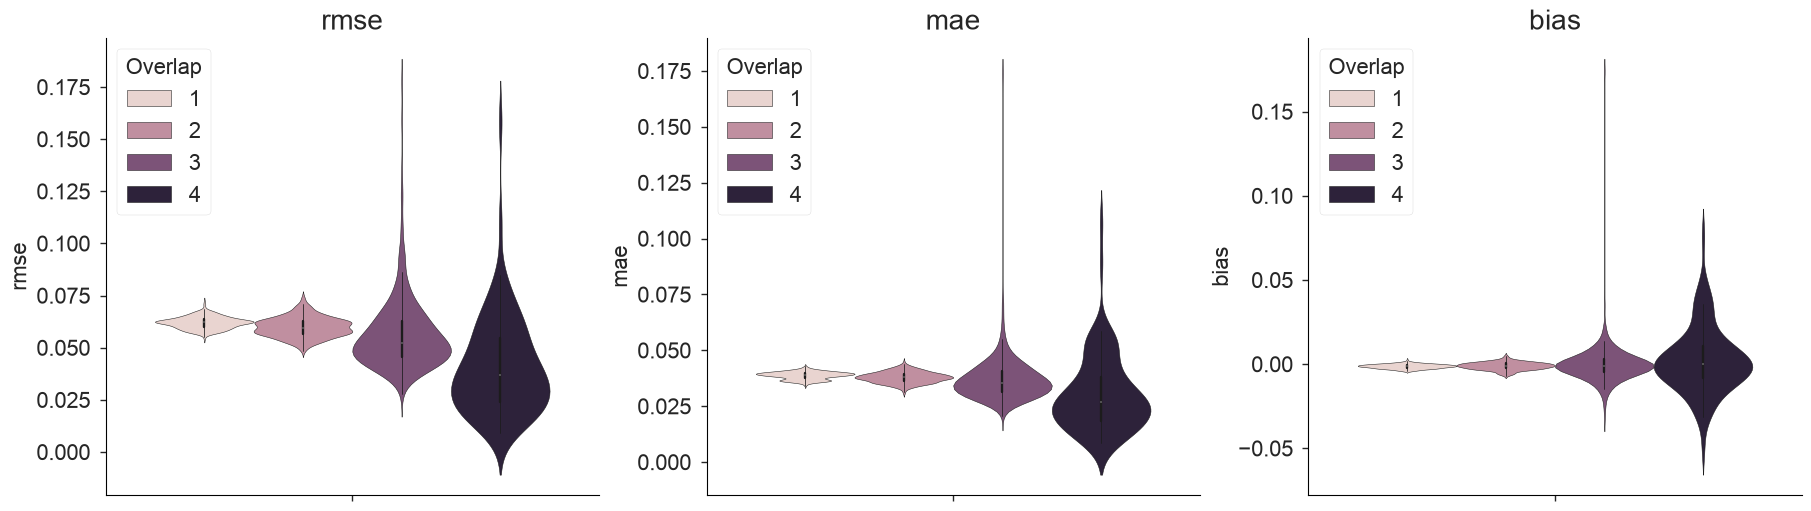

In [73]:
metric = "rmse"
metrics = ["rmse", "mae", "bias"]
ncols = len(metrics)
fig, axs = plt.subplots(1, ncols, figsize=(6*ncols,5))
for metric, ax in zip(metrics,axs):
    sns.violinplot(
        ods[metric].sel(group="pooled").to_dataset().to_dataframe().reset_index(),
        y=metric,
        hue="overlap",
        ax=ax,
    )
    ax.legend(title="Overlap");
    ax.set(title=metric)

## Plots using the old format

I'm not going to redo these because I can't redo inference with datasets with land points without recreating those datasets

In [47]:
ogds = [
    xr.open_dataset(f"runs/v{version}/metrics/sla.by_region.per_group.nc").squeeze().load().expand_dims({"version": [version]})
    for version in [0, 1, 2, 3, "3mft", 4]
]
ogds = xr.concat(ogds, dim="version")
ogds = ogds.drop_vars(["lead_time", "valid_time", "fhr"])
pds = (
    xr.open_dataset("runs/persistence-metrics/sla.pooled.per_group.nc").squeeze().load().expand_dims(
        {"version": ["pooled persistence"], "region": ["seen_at_t0"]})
).drop_vars(["lead_time", "fhr"])
ogds = xr.concat([ogds, pds], dim="version", join="outer")

In [48]:
def make_it_nice(ax):
    ax.set(
        xlabel="",
        ylabel=ax.get_ylabel().upper(),
        xticklabels=[x.get_text().replace("_"," ").capitalize() for x in ax.get_xticklabels()],
    )

In [49]:
def plot_observed_region(xds, metric, x="group", hue="region"):
    
    fig, ax = plt.subplots(figsize=(9,5))
    df = xds[metric].to_dataset().to_dataframe().reset_index()
    sns.violinplot(
        df,
        y=metric,
        x=x,
        #alpha=.5
        hue=hue,
    )

    groups = xds["group"].values
    if x == "group":
        stdev = sds["stdev"].sel(variable=[f"sla_filtered_{g}" for g in groups]).values
        x = np.arange(len(groups))
        
        ax.hlines(stdev, x - 0.4, x + 0.4, color="gray", lw=1.5, zorder=3,
                  label="Training Std. Dev.")
    else:
        stdev = sds["stdev"].sel(variable="pooled").values
        ax.axhline(stdev, color="gray", lw=1.5, zorder=3, label="Training Std. Dev.")
        
        
    l = ax.legend(bbox_to_anchor=(1., .5), loc="center left");
    
    make_it_nice(ax)
    return fig, ax

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_53641/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


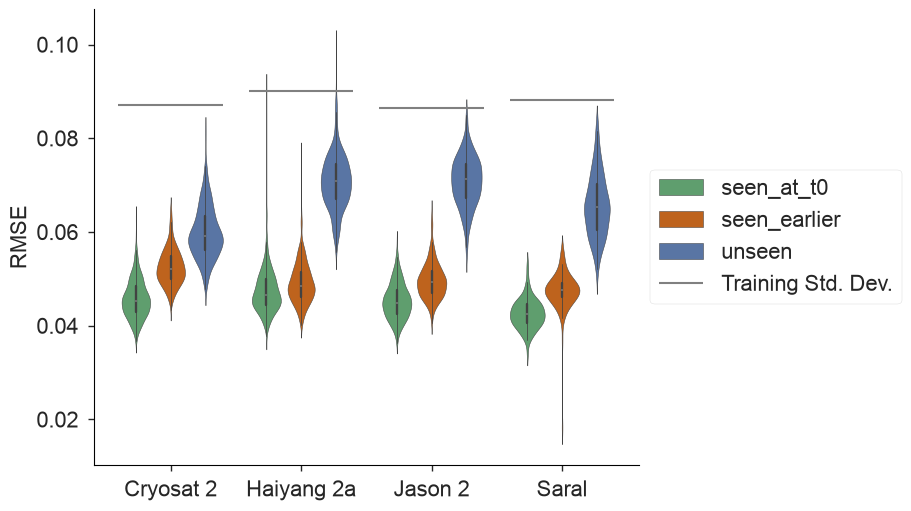

In [50]:
fig, ax = plot_observed_region(ogds.sel(version=3), "rmse");
#fig.savefig("runs/v3/figures/rmse_by_region_by_group.jpeg", bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_53641/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


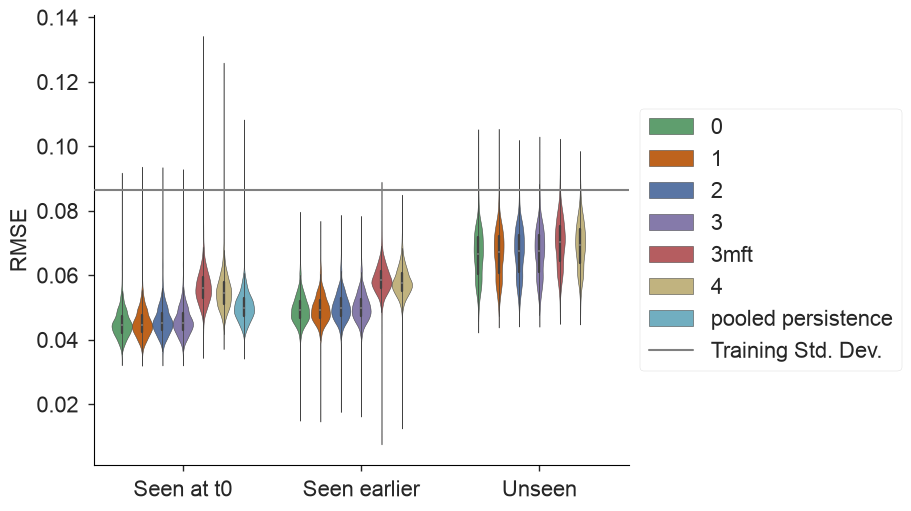

In [51]:
fig, ax = plot_observed_region(ogds, metric="rmse", x="region", hue="version")
fig.savefig(f"figures/rmse_vs_region_by_version.jpeg", dpi=300, bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_53641/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


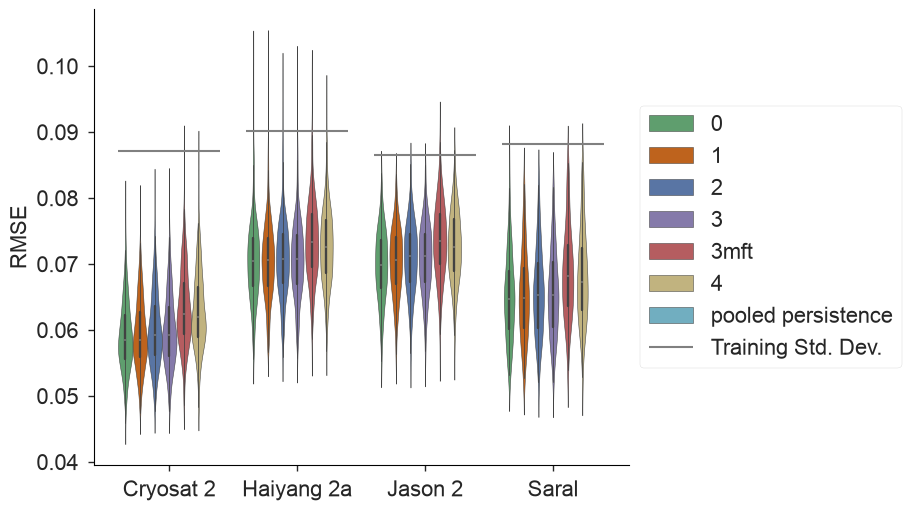

In [52]:
fig, ax = plot_observed_region(ogds.sel(region="unseen"), metric="rmse", hue="version")
#fig.savefig("figures/unseen_rmse_by_version_by_group.jpeg", bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_53641/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


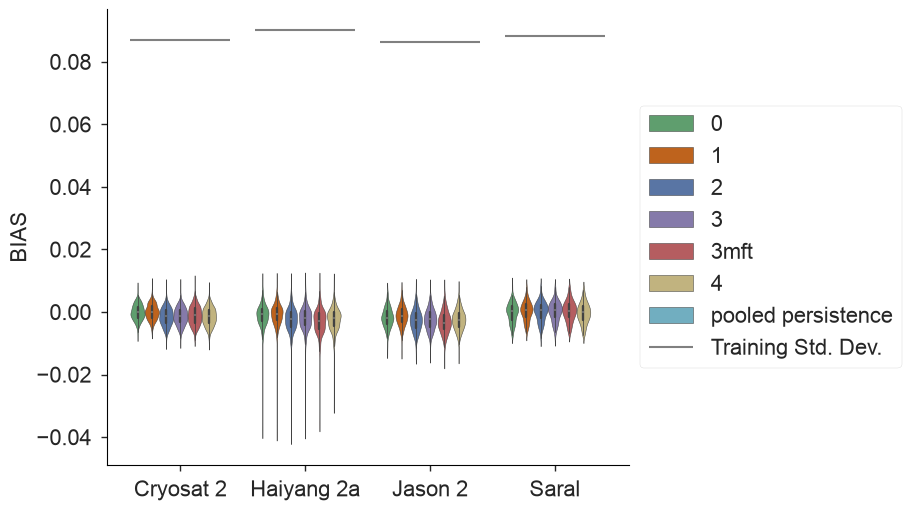

In [53]:
fig, ax = plot_observed_region(ogds.sel(region="unseen"), metric="bias", hue="version")
#fig.savefig("figures/unseen_bias_by_version_by_group.jpeg", bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_53641/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


(<Figure size 900x500 with 1 Axes>, <Axes: ylabel='RMSE'>)

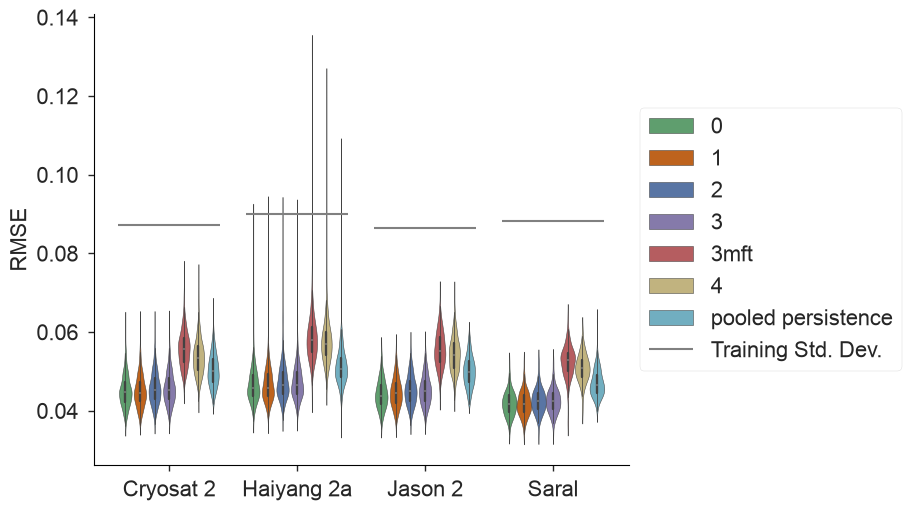

In [54]:
plot_observed_region(ogds.sel(region="seen_at_t0"), metric="rmse", hue="version")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_53641/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


(<Figure size 900x500 with 1 Axes>, <Axes: ylabel='RMSE'>)

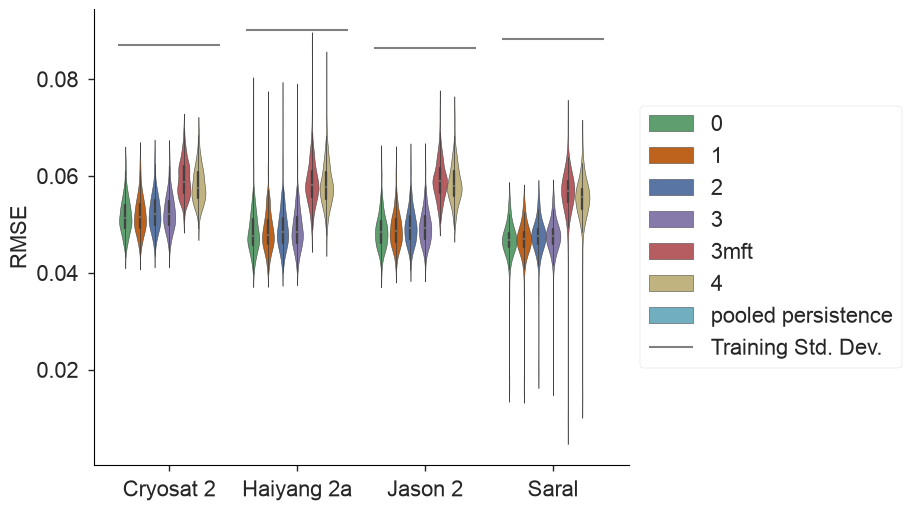

In [55]:
plot_observed_region(ogds.sel(region="seen_earlier"), metric="rmse", hue="version")

## Look at overlap degree

In [57]:
lgds = [
    xr.open_dataset(f"runs/v{version}/metrics/sla.by_overlap.per_group.nc").squeeze().load().expand_dims({"version": [version]})
    for version in [0, 1, 2, 3, "3mft", 4]
]
lgds = xr.concat(lgds, dim="version")
lgds.load()

<xarray.Dataset> Size: 1MB
Dimensions:     (version: 6, t0: 362, group: 4, n_overlap: 4)
Coordinates:
  * version     (version) object 48B 0 1 2 3 '3mft' 4
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 160B 'cryosat_2' 'haiyang_2a' 'jason_2' 'saral'
  * n_overlap   (n_overlap) int64 32B 1 2 3 4
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
Data variables:
    rmse        (version, t0, group, n_overlap) float64 278kB 0.04732 ... nan
    mae         (version, t0, group, n_overlap) float64 278kB 0.02961 ... nan
    bias        (version, t0, group, n_overlap) float64 278kB 0.001013 ... nan
    n_obs       (version, group, t0, n_overlap) int64 278kB 2417 906 139 ... 0 0

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_53641/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


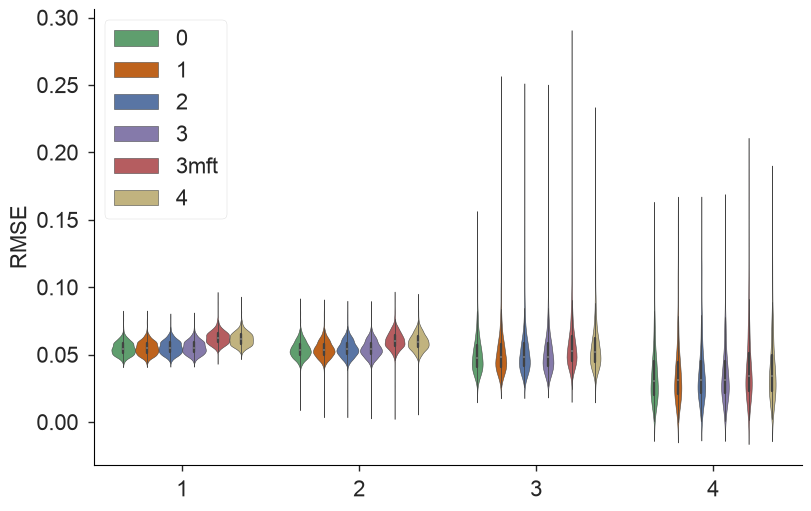

In [58]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(8,5))
df = lgds[metric].to_dataset().to_dataframe().reset_index()
sns.violinplot(
    df,
    x="n_overlap",
    y="rmse",
    hue="version",
)
ax.legend();
make_it_nice(ax)
#fig.savefig(f"runs/v3/figures/rmse_by_overlap.jpeg", bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_53641/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


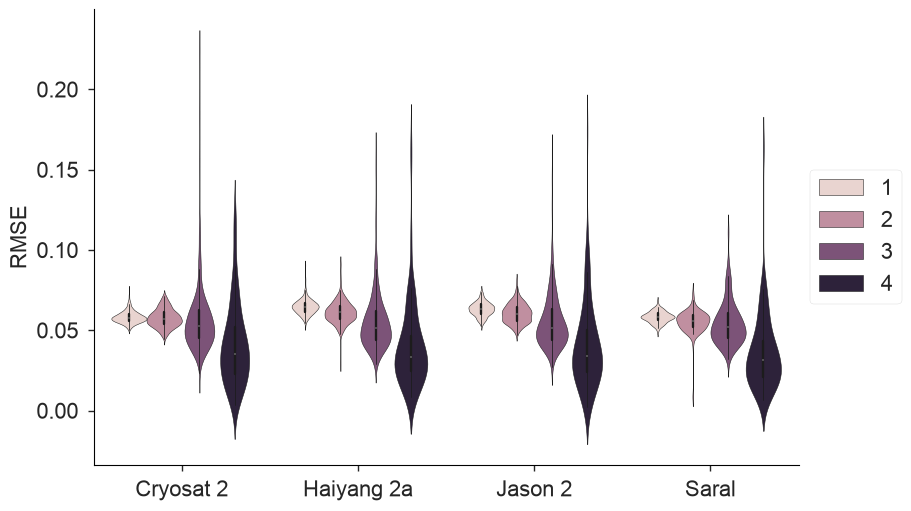

In [59]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(9,5))
df = lgds.sel(version=4)[metric].to_dataset().to_dataframe().reset_index()
sns.violinplot(
    df,
    y="rmse",
    x="group",
    #alpha=.5
    hue="n_overlap",
)

#groups = lgds["group"].values
#stdev = sds["stdev"].sel(variable=[f"sla_filtered_{g}" for g in groups]).values
#print(groups)
#x = np.arange(len(groups))
#
#ax.hlines(stdev, x - 0.4, x + 0.4, color="gray", lw=1.5, zorder=3,
#          label="Training Std. Dev.")
    
l = ax.legend(bbox_to_anchor=(1., .5), loc="center left");

make_it_nice(ax)
#fig.savefig(f"runs/v3/figures/rmse_by_overlap_by_group.jpeg", bbox_inches="tight")